<a href="https://colab.research.google.com/github/anytaaly/cershe-valence-arousal-data-analysis/blob/main/cershe_valence_arousal_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

* Valence and arousal labelled by Anyta Ali.
* The events are invented, fictitious scenarios. Any resemblance to actual events is coincidental.
* All rights reserved.


In [1]:
import re;
import matplotlib.pyplot as plt;
import numpy as np;
import pandas as pd;

In [3]:
text = open('stories-draft-001.txt', encoding='utf-8').read()

In [4]:
print(text[:300])

CERSHE EMOTIONAL-STATE TRAINING STORIES — DRAFT 001
Valence and arousal labelled by Anyta Ali.
The events are invented, fictitious scenarios. Any resemblance to actual events is coincidental.
All rights reserved.

SCALE
Valence: -1.00 (very unpleasant) to 1.00 (very pleasant). 0 is neutral.
Arousal:


In [5]:

#split the text into separate stories. In a new cell:
blocks = text.split('SEQUENCE: ')[1:]

In [6]:
print(blocks[1:])

['child_bullied_001\n\nPERSONA CONTEXT:\nMost relevant core value: kindness.\n\nSTARTING CONTEXT:\nNo unresolved event is currently affecting her.\nStarting valence: 0.10\nStarting arousal: 0.20\n\nSTEP 1\nElapsed minutes since previous step: 0\nEvent type: conversation\nEvent: A parent tells Cershe that their nine-year-old son is being bullied at school and no longer wants to go.\nUnresolved: child_bullying\nCore value related: 1\nCore value: kindness\n\nTarget valence: -0.70\nTarget arousal: 0.65\nAnnotation note: A child is being hurt and the parent is distressed. Concern and a wish to help.\n\nSTEP 2\nElapsed minutes since previous step: 20\nEvent type: time_only\nEvent: No new information or reminders.\nCore value related: 0\n\nTarget valence: -0.60\nTarget arousal: 0.45\nAnnotation note: Activation eases after the conversation ends; the concern for the child remains.\n\nSTEP 3\nElapsed minutes since previous step: 2880\nEvent type: time_only\nEvent: No new information or reminder

In [7]:
len(blocks)

9

In [8]:
story = blocks[0]

In [9]:
#pull out her valence at each step. In a new cell:
valence = [float(v) for v in re.findall(r'Target valence: (-?[\d.]+)', story)]





In [10]:
arousal = [float(v) for v in re.findall(r'Target arousal: ([\d.]+)', story)]

In [11]:
print(valence)
print(arousal)

[-0.5, -0.7, -0.4, -0.2, -0.1, 0.25, 0.0]
[0.8, 0.75, 0.6, 0.35, 0.22, 0.4, 0.22]


In [12]:
types = re.findall(r'Event type: (\w+)', story)

In [13]:
print(types)

['news', 'time_only', 'time_only', 'memory_recall', 'time_only', 'news', 'time_only']


In [14]:
core = [int(c) for c in re.findall(r'Core value related: ([01])', story)]
minutes = [int(m) for m in re.findall(r'Elapsed minutes since previous step: (\d+)', story)]

In [15]:
# X axis is steps, not time. Step 1, step 2 and so on are spaced evenly, even though the real gaps between them are very different:
# Real time is best for seeing how feelings fade. But a one-week gap would squash the 5- and 30-minute steps into a single blob at the start.
# plt.plot(range(1, len(valence) + 1), valence, marker='o', color='#5E8FEA', label='Valence')


In [34]:
# cumulative time passed
total = [sum(minutes[:i + 1]) for i in range(len(minutes))]

In [35]:
print(total)

[0, 30, 1470, 1475, 1595, 11675, 11855]


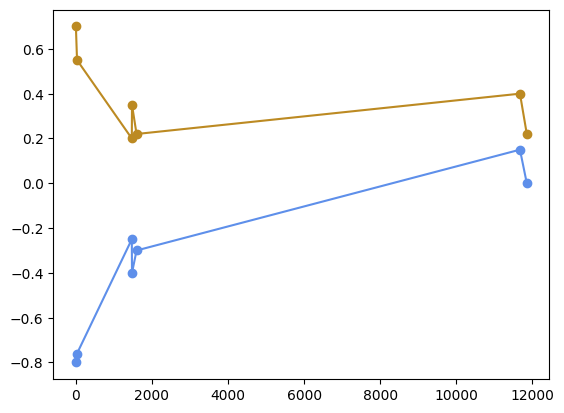

In [39]:
plt.plot(total, valence, marker='o', color='#5E8FEA', label='Valence') ## Valence is blue
plt.plot(total, arousal, marker='o', color='#BC8A22', label='Arousal') ## Arousal is Yellow


In [17]:
total = [sum(minutes[:i + 1]) for i in range(len(minutes))]

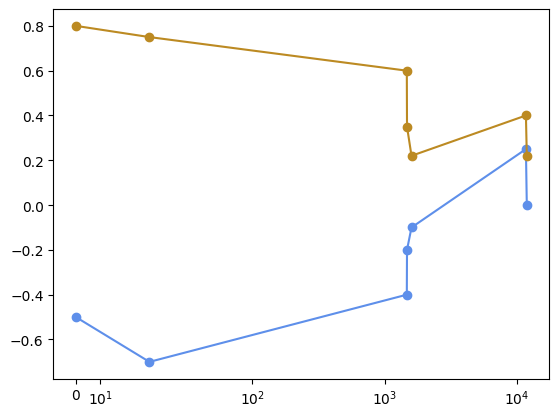

In [18]:
plt.plot(total, valence, marker='o', color='#5E8FEA', label='Valence') ## Valence is blue
plt.plot(total, arousal, marker='o', color='#BC8A22', label='Arousal') ## Arousal is Yellow
plt.xscale('symlog', linthresh=60)

# symlog stretches the axis so each step up in time scale gets equal room: minutes, hours, days, weeks. Then the first half-hour isn’t crushed against the left edge.

(-1.0, 1.0)

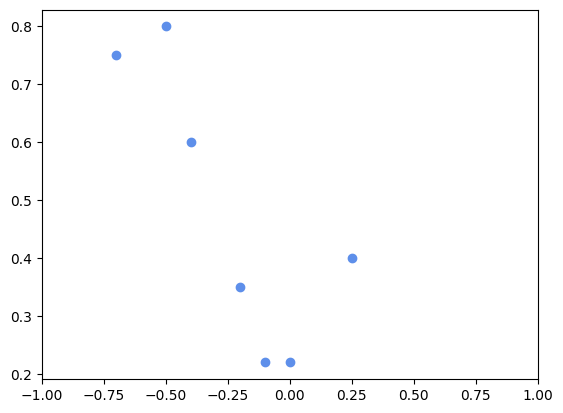

In [20]:
plt.scatter(valence, arousal, color='#5E8FEA')
plt.xlim(-1, 1)